<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/car_evaluation_classification_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. 데이터 불러오기 + 컬럼명 부여
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/car.data',
                 header=None,
                 names=['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'])
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [13]:
# 2. 데이터 확인 + 결측치 확인
print(df.shape)
print(df.isnull().sum())
print(df["class"].value_counts())

(1728, 7)
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [14]:
# 3. EDA: 각 입력 특성의 값 분포 확인
for col in ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']:
    print(f"[{col}]")
    print(df[col].value_counts(), "\n")

[buying]
buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64 

[maint]
maint
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64 

[doors]
doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64 

[persons]
persons
2       576
4       576
more    576
Name: count, dtype: int64 

[lug_boot]
lug_boot
small    576
med      576
big      576
Name: count, dtype: int64 

[safety]
safety
low     576
med     576
high    576
Name: count, dtype: int64 



In [15]:
# 4. 입력 특성 원-핫 인코딩
feature_cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']
X = pd.get_dummies(df[feature_cols], dtype=int)
print("입력 특성 개수:", X.shape[1])   # 6개 특성 -> 원-핫 후 21개 컬럼
X.head()

입력 특성 개수: 21


,buying_high,buying_low,buying_med,buying_vhigh,maint_high,maint_low,maint_med,maint_vhigh,doors_2,doors_3,...,doors_5more,persons_2,persons_4,persons_more,lug_boot_big,lug_boot_med,lug_boot_small,safety_high,safety_low,safety_med
0,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,1,0
1,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,0,1
2,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,1,0,0
3,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
4,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,1


In [16]:
# 5. 정답(class) 인코딩
# 정답은 unacc/acc/good/vgood 4개 범주 -> 0/1/2/3 숫자로 변환
le = LabelEncoder()
y = le.fit_transform(df["class"])
print("클래스:", list(le.classes_))   # ['acc', 'good', 'unacc', 'vgood']
print("예시:", df["class"][:5].tolist(), "->", y[:5])

클래스: ['acc', 'good', 'unacc', 'vgood']
예시: ['unacc', 'unacc', 'unacc', 'unacc', 'unacc'] -> [2 2 2 2 2]


In [17]:
# 6. 학습 / 테스트 데이터 분리
# stratify=y: 클래스 비율이 불균형하므로 학습/테스트에 같은 비율로 나뉘도록 함
X = X.values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. 정답 원-핫 인코딩
# 클래스가 3개 이상이면 softmax 출력(4칸)과 모양을 맞추기 위해 정답도 [0,0,1,0] 형태로 바꿈
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=4)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=4)
print(y_train[:3], "->", y_train_oh[:3].tolist())

[0 2 0] -> [[1.0, 0.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [1.0, 0.0, 0.0, 0.0]]


In [18]:
# 8. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(X.shape[1],)))   # 입력: 원-핫 컬럼 개수
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(4, activation="softmax"))   # 다중 분류: 4개 클래스 확률 (합 = 1)

# 9. 모델 설정
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [19]:
# 10. 모델 구조 출력
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,300 (5.08 KB)

 Trainable params: 1,300 (5.08 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# 11. 모델 학습
history = model.fit(X_train, y_train_oh, epochs=100, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3719 - loss: 1.3212 - val_accuracy: 0.6643 - val_loss: 1.1401
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7014 - loss: 1.0109 - val_accuracy: 0.6823 - val_loss: 0.9137
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7050 - loss: 0.7796 - val_accuracy: 0.6823 - val_loss: 0.7087
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7430 - loss: 0.6074 - val_accuracy: 0.7473 - val_loss: 0.6041
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8054 - loss: 0.5180 - val_accuracy: 0.7834 - val_loss: 0.5376
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8335 - loss: 0.4455 - val_accuracy: 0.8375 - val_loss: 0.4724
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8552 - loss: 0.3905 - val_accuracy: 0.8448 - val_loss: 0.4287
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8778 - loss: 0.3486 - val_accuracy: 0.8448 - 

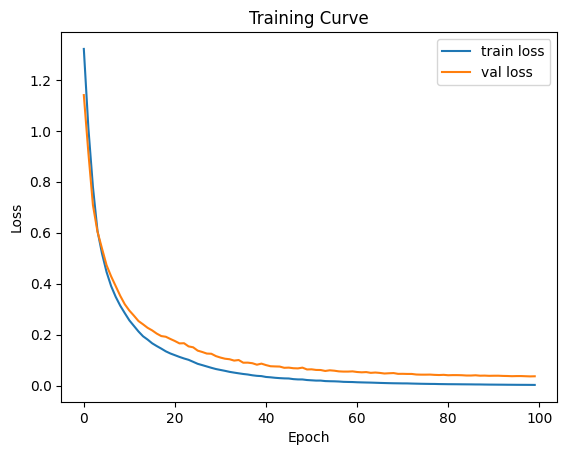

In [21]:
# 12. 학습 곡선 시각화
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Curve")
plt.show()

In [22]:
# 13. 테스트 데이터 예측
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [23]:
# 14. 성능 평가
print("Accuracy =", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy = 0.9971098265895953
[[ 77   0   0   0]
 [  0  14   0   0]
 [  1   0 241   0]
 [  0   0   0  13]]
              precision    recall  f1-score   support

         acc       0.99      1.00      0.99        77
        good       1.00      1.00      1.00        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      1.00      1.00        13

    accuracy                           1.00       346
   macro avg       1.00      1.00      1.00       346
weighted avg       1.00      1.00      1.00       346

